In [21]:
from abacusnbody.data.read_abacus import read_asdf
import numpy as np
import matplotlib.pyplot as plt
#from abacusnbody.analysis.tpcf_corrfunc import calc_power
import os
from astropy.table import vstack
from pycorr.correlation_function import TwoPointCorrelationFunction

In [12]:
mapdir = "maps_072926/MapTune_bmerge_proper_0p01_Amerge_36p707/maplogs/col000"

#read in files
filelist = []
for root, dirs, files in os.walk(mapdir):
    for file in files:
        if "asdf" in file:
            filelist.append(root+"/"+file)

In [16]:
tables = [read_asdf(file,load='all') for file in filelist]
tab = vstack(tables)

#Position is returned in Mpc/h (5 kpc/h quantum, fixed); velocity in km/s

In [17]:
tab

pos,vel,mult,control,node_type,timestep,mult_sec,pid,density,vel_disp,length,vel_rel,lc_label
float32[3],float32[3],int32,uint16,uint8,int32,int32,uint16[3],float32,float32,int32,float32,uint8
-92.05469 .. -66.921875,-340.0 .. 222.0,29,2663,3,665,0,0 .. 0,31.0,84.0,2,120.0,0
-90.60156 .. -67.90625,-196.0 .. 164.0,21,1520,0,380,0,38456 .. 0,0.0,0.0,0,0.0,0
-92.17969 .. -66.84375,-248.0 .. 200.0,33,2663,3,665,0,0 .. 0,52.0,94.0,4,25.0,0
-90.4375 .. -67.953125,-262.0 .. 208.0,27,1503,3,375,0,0 .. 0,34.0,104.0,3,49.0,0
-90.30469 .. -68.0625,-218.0 .. 188.0,27,1419,3,354,0,0 .. 0,31.0,94.0,2,23.0,0
-89.60156 .. -68.578125,-216.0 .. 138.0,21,940,0,235,0,38706 .. 0,0.0,0.0,0,0.0,0
-91.5625 .. -67.08594,-372.0 .. 176.0,38,2663,3,665,0,0 .. 0,15.0,76.0,4,88.0,0
-89.99219 .. -68.08594,-230.0 .. 164.0,20,1503,3,375,0,0 .. 0,14.0,74.0,3,14.0,0
-89.85156 .. -68.17969,-246.0 .. 158.0,20,1419,3,354,0,0 .. 0,16.0,72.0,2,5.0,0


In [ ]:
#Just get a handle on what we're looking at
tab['x'] = tab['pos'][:,0]
tab['y'] = tab['pos'][:,1]
tab['z'] = tab['pos'][:,2]

In [ ]:
#let's select all the maps at redshift 0.2 (I think?), timestep 665
#we need node_type 3
#we will then plot a correlation function by metallicity
maps_z0_2 = tab[(tab['node_type'] == 3)&(tab['timestep']==665)]
print(len(maps_z0_2))

761563
4855787


Text(0, 0.5, 'Number of MAPs')

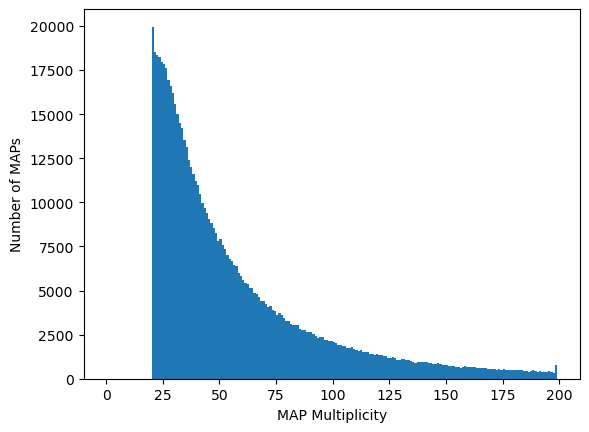

In [36]:
plt.hist(maps_z0_2['mult'],bins=np.arange(0,200))
plt.xlabel("MAP Multiplicity")
plt.ylabel("Number of MAPs")

(array([460915., 520887., 510047., 480616., 529267., 468257., 454937.,
        509190., 475871., 445800.]),
 array([-1.02757812e+02, -8.22265625e+01, -6.16953125e+01, -4.11640625e+01,
        -2.06328125e+01, -1.01562500e-01,  2.04296875e+01,  4.09609375e+01,
         6.14921875e+01,  8.20234375e+01,  1.02554688e+02]),
 <BarContainer object of 10 artists>)

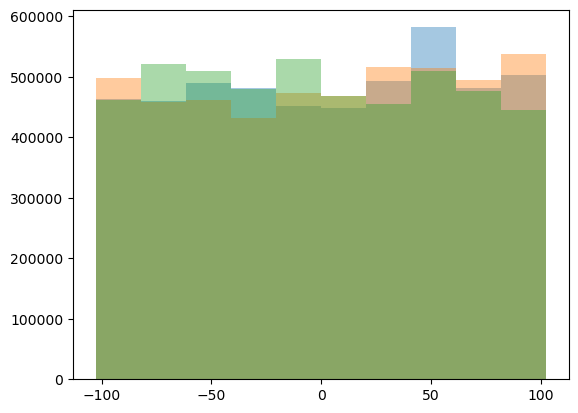

In [ ]:
#calculate the correlation function